# 01 — SegFormer-B0 prototype (early exploration)

First end-to-end sketch of the pipeline: SegFormer-B0 (ADE20K weights) with a new 9-class head, CE + Dice loss, and a pseudo-label/confidence-map dump for the unlabeled set. Run locally on CPU; the training cell was interrupted and this notebook did **not** produce a submission.

> Needs the organizer-provided `utils.py` from the challenge starter kit (not redistributed in this repo) for `plot_class_RGBcolors`.

See the [project README](../README.md) for the full write-up.

### Imports

In [1]:
import os
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from utils import *

# Import SegFormer from Hugging Face Transformers
from transformers import SegformerForSemanticSegmentation

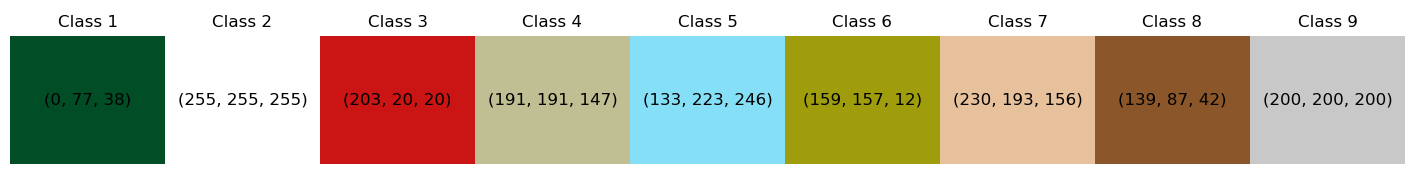

In [2]:
class_dict = {
    1: (0, 77, 38),
    2: (255, 255, 255),
    3: (203, 20, 20),
    4: (191, 191, 147),
    5: (133, 223, 246),
    6: (159, 157, 12),
    7: (230, 193, 156),
    8: (139, 87, 42),
    9: (200, 200, 200),
}
plot_class_RGBcolors(class_dict)

In [3]:
def create_label_mask(image, class_dict):
    """
    Create a label mask for an image based on a class dictionary.

    This function loads an image, converts it to a numpy array, and creates a label mask where each pixel
    is assigned a class label based on its RGB value. The class labels are determined using a provided
    class dictionary that maps RGB values to class labels.

    Parameters:
    image_path (str): Path to the image file.
    class_dict (dict): Dictionary where keys are class labels (int) and values are RGB values (list of three ints).

    Returns:
    numpy.ndarray: A 2D numpy array where each element is a class label corresponding to the pixel in the image.
    """
    # Load the image and convert it to a numpy array
    image_array = np.asarray(image)

    # Initialize the mask with zeros
    mask = np.zeros((image_array.shape[1], image_array.shape[2]), dtype=np.uint8)

    # Create a reverse dictionary for quick lookup
    reverse_class_dict = {tuple(v): k for k, v in class_dict.items()}

    # Create a 2D array of tuples representing the RGB values
    rgb_tuples = image_array.reshape(-1, 3)

    # Create a 1D array to store the class labels
    labels = np.zeros(rgb_tuples.shape[0], dtype=np.uint8)

    # Assign class labels based on RGB values
    for rgb, class_label in reverse_class_dict.items():
        mask_indices = np.all(rgb_tuples == rgb, axis=1)
        labels[mask_indices] = class_label

    # Reshape the labels array back to the original image shape
    mask = labels.reshape(image_array.shape[1], image_array.shape[2])

    return mask

### 1. Define Loss Functions: Dice Loss + Combined Loss

In [4]:
def dice_loss(pred, target, eps=1e-6):
    """
    Computes the Dice loss.
    Args:
        pred: Tensor of shape (B, C, H, W) containing probabilities (after softmax).
        target: Tensor of shape (B, H, W) with ground-truth class indices.
    Returns:
        Dice loss (1 - Dice coefficient averaged over classes).
    """
    num_classes = pred.shape[1]
    # Convert target to one-hot encoding: shape (B, H, W, C) then permute to (B, C, H, W)
    target_one_hot = F.one_hot(target, num_classes=num_classes).permute(0, 3, 1, 2).float()
    
    # Sum over batch and spatial dimensions
    dims = (0, 2, 3)
    intersection = torch.sum(pred * target_one_hot, dims)
    cardinality = torch.sum(pred + target_one_hot, dims)
    dice_score = (2. * intersection + eps) / (cardinality + eps)
    
    # Dice loss per class is (1 - dice_score); average over classes
    return 1 - dice_score.mean()

class CombinedLoss(nn.Module):
    """
    Combined loss: Cross-Entropy Loss + Dice Loss.
    """
    def __init__(self, weight_ce=1.0, weight_dice=1.0):
        super(CombinedLoss, self).__init__()
        self.weight_ce = weight_ce
        self.weight_dice = weight_dice
        self.ce_loss = nn.CrossEntropyLoss()
        
    def forward(self, logits, target):
        # logits: (B, C, H, W)
        ce = self.ce_loss(logits, target)
        # Compute probabilities using softmax over class dimension
        probs = F.softmax(logits, dim=1)
        d_loss = dice_loss(probs, target)
        return self.weight_ce * ce + self.weight_dice * d_loss

### 2. Dataset Classes for Labeled and Unlabeled Data

In [5]:
class LabeledDataset(Dataset):
    """
    Dataset for labeled images.
    Assumes:
      - In data/train, image files end with ".png" and do NOT contain the string "lab".
      - Corresponding mask files are named: <image_basename> + "_lab.png"
    """
    def __init__(self, data_dir, image_transform=None, mask_transform=None):
        self.data_dir = data_dir
        self.image_transform = image_transform
        self.mask_transform = mask_transform
        # List image files that are not masks
        self.image_files = [f for f in os.listdir(data_dir)
                            if f.endswith('.png') and 'img' in f]
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        image_file = self.image_files[idx]
        image_path = os.path.join(self.data_dir, image_file)
        # Construct the corresponding mask file name (e.g., "core_img.png" -> "core_lab.png")
        mask_file = image_file.replace('_img.png', '_lab.png')
        mask_path = os.path.join(self.data_dir, mask_file)
        
        try:
            image = Image.open(image_path).convert("RGB")
            mask = Image.open(mask_path)

        except FileNotFoundError as e:
            print(f"Error: File not found: {e}")
            return None  # Or handle differently
            
        if self.image_transform:
            image = self.image_transform(image)
        if self.mask_transform:
            mask = self.mask_transform(mask)
            label_mask = create_label_mask(mask, class_dict).astype(np.int64)
            
        return image, label_mask

class UnlabeledDataset(Dataset):
    """
    Dataset for unlabeled images.
    Returns the image tensor and its filename.
    """
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.image_files = [f for f in os.listdir(data_dir) if f.endswith('.png')]
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        image_file = self.image_files[idx]
        image_path = os.path.join(self.data_dir, image_file)
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, image_file

### 3. Define Transforms

In [6]:
# For training images (and masks) you may want to resize and normalize.
# Adjust the image size as needed (here, 512x512 is used as an example).

train_image_transform = transforms.Compose([
    transforms.Resize((1200, 300)),
    transforms.ToTensor(),
    # Normalize with ImageNet means and stds (adjust if necessary)
    transforms.Normalize(mean=[0.658, 0.611, 0.486],
                         std=[0.276, 0.287, 0.362])
])

# For masks, use nearest-neighbor interpolation to avoid creating spurious label values.
train_mask_transform = transforms.Compose([
    transforms.Resize((300, 75), interpolation=Image.NEAREST),
    transforms.ToTensor(),  # This will produce a tensor of shape (1, H, W)
])

# For inference, similar transforms (except no augmentation)
inference_transform = transforms.Compose([
    transforms.Resize((1200, 300)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.658, 0.611, 0.486],
                         std=[0.276, 0.287, 0.362])
])

### 4. Create Datasets and Dataloaders

In [7]:
labeled_data_dir = os.path.join('data', 'train')
unlabeled_data_dir = os.path.join('data', 'train_unlabeled')

labeled_dataset = LabeledDataset(labeled_data_dir,
                                 image_transform=train_image_transform,
                                 mask_transform=train_mask_transform)
labeled_loader = DataLoader(labeled_dataset, batch_size=4, shuffle=True, num_workers=0)

unlabeled_dataset = UnlabeledDataset(unlabeled_data_dir, transform=inference_transform)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=1, shuffle=False)

### 5. Initialize the Model, Loss, and Optimizer

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Set the number of classes (adjust according to your dataset)
NUM_CLASSES = 9

# Load a pretrained SegFormer model and adjust the number of labels
model_name = "nvidia/segformer-b0-finetuned-ade-512-512"
model = SegformerForSemanticSegmentation.from_pretrained(model_name, num_labels=NUM_CLASSES, ignore_mismatched_sizes=True)
model.to(device)

# Instantiate the combined loss and the optimizer
criterion = CombinedLoss(weight_ce=1.0, weight_dice=1.0)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([9]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([9, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


### 6. Training Loop on Labeled Data

In [9]:
num_epochs = 10  # Adjust as needed

model.train()
for epoch in range(num_epochs):
    running_loss = 0.0
    for images, masks in labeled_loader:
        images = images.to(device)       # Shape: (B, 3, H, W)
        masks = masks.to(device)         # Shape: (B, H, W)
        
        optimizer.zero_grad()
        # For Hugging Face SegFormer, pass the images as "pixel_values"
        outputs = model(pixel_values=images).logits  # Shape: (B, NUM_CLASSES, H, W)
        
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    avg_loss = running_loss / len(labeled_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

KeyboardInterrupt: 

### 7. Inference on Unlabeled Data: Generate Pseudo Masks with Confidences

In [ ]:
model.eval()
pseudo_masks = {}  # Dictionary to store results for each image

with torch.no_grad():
    for image, image_file in unlabeled_loader:
        image = image.to(device)
        output = model(pixel_values=image).logits  # (1, NUM_CLASSES, H, W)
        # Convert logits to probabilities
        probs = F.softmax(output, dim=1)  # (1, NUM_CLASSES, H, W)
        
        # For each pixel, get the predicted class (argmax) and the corresponding confidence (max probability)
        confidence, pseudo_mask = torch.max(probs, dim=1)  # Both tensors of shape (1, H, W)
        pseudo_mask = pseudo_mask.squeeze(0).cpu().numpy().astype(np.uint8)
        confidence = confidence.squeeze(0).cpu().numpy()  # Confidence map
        
        # Store using the image filename as key
        pseudo_masks[image_file[0]] = {'mask': pseudo_mask, 'confidence': confidence}

# Optionally, save the pseudo masks and confidence maps to disk.
output_dir = os.path.join('data', 'pseudo_labels')
os.makedirs(output_dir, exist_ok=True)

for filename, data_dict in pseudo_masks.items():
    mask = data_dict['mask']
    conf = data_dict['confidence']
    
    # Save pseudo mask as a PNG image
    mask_img = Image.fromarray(mask)
    mask_filename = filename.replace('.png', '_pseudo_mask.png')
    mask_img.save(os.path.join(output_dir, mask_filename))
    
    # Save confidence map as a numpy file (or convert to an image after scaling)
    conf_filename = filename.replace('.png', '_confidence.npy')
    np.save(os.path.join(output_dir, conf_filename), conf)

print("Pseudo labeling complete. Pseudo masks and confidence maps saved in:", output_dir)